# HAM10000 Skin Lesion Classification: Dataset Inspection, Leakage-Free Data Splitting, and Environment Setup

In [1]:

import os

for root, dirs, files in os.walk("/kaggle/input"):
    level = root.replace("/kaggle/input", "").count(os.sep)

    if level > 3:
        dirs[:] = []
        continue

    print(f"\n📁 {root}")
    for d in dirs[:15]:
        print(f"   📂 {d}")
    for f in files[:15]:
        print(f"   📄 {f}")



📁 /kaggle/input
   📂 datasets

📁 /kaggle/input/datasets
   📂 kmader

📁 /kaggle/input/datasets/kmader
   📂 skin-cancer-mnist-ham10000

📁 /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000
   📂 HAM10000_images_part_1
   📂 HAM10000_images_part_2
   📂 ham10000_images_part_1
   📂 ham10000_images_part_2
   📄 HAM10000_metadata.csv
   📄 hmnist_28_28_L.csv
   📄 hmnist_28_28_RGB.csv
   📄 hmnist_8_8_L.csv
   📄 hmnist_8_8_RGB.csv


In [2]:

import os
import pandas as pd

ROOT = "/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000"

# Inspect metadata
df = pd.read_csv(os.path.join(ROOT, "HAM10000_metadata.csv"))

print("METADATA SHAPE:", df.shape)
print("\nCOLUMNS:", df.columns.tolist())
print("\nFIRST 5 ROWS:")
display(df.head())

print("\nMISSING VALUES:")
print(df.isnull().sum())

print("\nIMAGE COUNTS BY DIAGNOSIS:")
print(df["dx"].value_counts())

print("\nUNIQUE LESIONS:", df["lesion_id"].nunique())
print("DUPLICATE IMAGE IDs:", df["image_id"].duplicated().sum())
print("DUPLICATE LESION IDS:", df["lesion_id"].duplicated().sum())

# Count actual images in all four folders
folders = [
    "HAM10000_images_part_1",
    "HAM10000_images_part_2",
    "ham10000_images_part_1",
    "ham10000_images_part_2",
]

all_images = []
for folder in folders:
    path = os.path.join(ROOT, folder)
    files = [
        f for f in os.listdir(path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ] if os.path.isdir(path) else []

    print(f"\n{folder}: {len(files)} images")
    all_images.extend(files)

print("\nTOTAL IMAGE FILES ACROSS FOLDERS:", len(all_images))
print("UNIQUE FILENAMES:", len(set(all_images)))
print("METADATA IMAGES MISSING FROM FOLDERS:",
      len(set(df["image_id"].astype(str)) - set(all_images)))


METADATA SHAPE: (10015, 7)

COLUMNS: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']

FIRST 5 ROWS:


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear



MISSING VALUES:
lesion_id        0
image_id         0
dx               0
dx_type          0
age             57
sex              0
localization     0
dtype: int64

IMAGE COUNTS BY DIAGNOSIS:
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64

UNIQUE LESIONS: 7470
DUPLICATE IMAGE IDs: 0
DUPLICATE LESION IDS: 2545

HAM10000_images_part_1: 5000 images

HAM10000_images_part_2: 5015 images

ham10000_images_part_1: 5000 images

ham10000_images_part_2: 5015 images

TOTAL IMAGE FILES ACROSS FOLDERS: 20030
UNIQUE FILENAMES: 10015
METADATA IMAGES MISSING FROM FOLDERS: 10015


In [3]:

import os
import pandas as pd

ROOT = "/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000"
df = pd.read_csv(os.path.join(ROOT, "HAM10000_metadata.csv"))

# Use the two uppercase folders to avoid counting duplicate copies twice
image_dirs = [
    os.path.join(ROOT, "HAM10000_images_part_1"),
    os.path.join(ROOT, "HAM10000_images_part_2"),
]

image_paths = {}
for folder in image_dirs:
    for filename in os.listdir(folder):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            image_id = os.path.splitext(filename)[0]
            image_paths.setdefault(
                image_id, os.path.join(folder, filename)
            )

metadata_ids = set(df["image_id"].astype(str))
available_ids = set(image_paths)

print("Metadata rows:", len(df))
print("Unique available image IDs:", len(available_ids))
print("Metadata images missing:", len(metadata_ids - available_ids))
print("Images absent from metadata:", len(available_ids - metadata_ids))

# Image-level and lesion-level class counts
print("\nIMAGE COUNTS BY DIAGNOSIS:")
print(df["dx"].value_counts().sort_index())

print("\nUNIQUE LESIONS BY DIAGNOSIS:")
print(df.groupby("dx")["lesion_id"].nunique().sort_index())

# Check whether each lesion has only one diagnosis
diagnoses_per_lesion = df.groupby("lesion_id")["dx"].nunique()
print("\nLesions linked to multiple diagnoses:",
      (diagnoses_per_lesion > 1).sum())

# Show how many images belong to each lesion
images_per_lesion = df.groupby("lesion_id")["image_id"].count()
print("\nLesions with multiple images:",
      (images_per_lesion > 1).sum())
print("Maximum images for one lesion:", images_per_lesion.max())
print("\nImages per lesion frequency:")
print(images_per_lesion.value_counts().sort_index())


Metadata rows: 10015
Unique available image IDs: 10015
Metadata images missing: 0
Images absent from metadata: 0

IMAGE COUNTS BY DIAGNOSIS:
dx
akiec     327
bcc       514
bkl      1099
df        115
mel      1113
nv       6705
vasc      142
Name: count, dtype: int64

UNIQUE LESIONS BY DIAGNOSIS:
dx
akiec     228
bcc       327
bkl       727
df         73
mel       614
nv       5403
vasc       98
Name: lesion_id, dtype: int64

Lesions linked to multiple diagnoses: 0

Lesions with multiple images: 1956
Maximum images for one lesion: 6

Images per lesion frequency:
image_id
1    5514
2    1423
3     490
4      34
5       5
6       4
Name: count, dtype: int64


In [4]:

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

# Work with the verified metadata
data = df.copy()

# First split: reserve one fold for testing
outer = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=42
)
trainval_idx, test_idx = next(
    outer.split(data, y=data["dx"], groups=data["lesion_id"])
)

trainval = data.iloc[trainval_idx].copy().reset_index(drop=True)
test = data.iloc[test_idx].copy().reset_index(drop=True)

# Second split: reserve one fold of trainval for validation
inner = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=43
)
train_idx, val_idx = next(
    inner.split(trainval, y=trainval["dx"], groups=trainval["lesion_id"])
)

train = trainval.iloc[train_idx].copy().reset_index(drop=True)
val = trainval.iloc[val_idx].copy().reset_index(drop=True)

# Verify no lesion group appears across splits
train_groups = set(train["lesion_id"])
val_groups = set(val["lesion_id"])
test_groups = set(test["lesion_id"])

print("SPLIT IMAGE COUNTS")
print("Train:", len(train))
print("Validation:", len(val))
print("Test:", len(test))
print("Total:", len(train) + len(val) + len(test))

print("\nUNIQUE LESION GROUPS")
print("Train:", len(train_groups))
print("Validation:", len(val_groups))
print("Test:", len(test_groups))

print("\nSHARED GROUPS (MUST ALL BE ZERO)")
print("Train ∩ Validation:", len(train_groups & val_groups))
print("Train ∩ Test:", len(train_groups & test_groups))
print("Validation ∩ Test:", len(val_groups & test_groups))

print("\nCLASS COUNTS BY SPLIT")
for name, split in [
    ("Train", train), ("Validation", val), ("Test", test)
]:
    print(f"\n{name}:")
    print(split["dx"].value_counts().sort_index())

# Ensure every class appears in every split
all_classes = set(data["dx"].unique())
for name, split in [
    ("Train", train), ("Validation", val), ("Test", test)
]:
    missing = all_classes - set(split["dx"].unique())
    print(f"{name} missing classes:", sorted(missing))

# Save split manifests for later reproducibility
train.to_csv("/kaggle/working/train_manifest.csv", index=False)
val.to_csv("/kaggle/working/val_manifest.csv", index=False)
test.to_csv("/kaggle/working/test_manifest.csv", index=False)

print("\nSaved train_manifest.csv, val_manifest.csv, and test_manifest.csv")


SPLIT IMAGE COUNTS
Train: 6380
Validation: 1621
Test: 2014
Total: 10015

UNIQUE LESION GROUPS
Train: 4781
Validation: 1194
Test: 1495

SHARED GROUPS (MUST ALL BE ZERO)
Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0

CLASS COUNTS BY SPLIT

Train:
dx
akiec     208
bcc       329
bkl       705
df         75
mel       683
nv       4299
vasc       81
Name: count, dtype: int64

Validation:
dx
akiec      51
bcc        85
bkl       189
df         18
mel       208
nv       1043
vasc       27
Name: count, dtype: int64

Test:
dx
akiec      68
bcc       100
bkl       205
df         22
mel       222
nv       1363
vasc       34
Name: count, dtype: int64
Train missing classes: []
Validation missing classes: []
Test missing classes: []

Saved train_manifest.csv, val_manifest.csv, and test_manifest.csv


In [6]:

from concurrent.futures import ThreadPoolExecutor
from collections import defaultdict
import hashlib
import os

def hash_image(item):
    image_id, path = item
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return image_id, h.hexdigest()

hash_groups = defaultdict(list)

with ThreadPoolExecutor(max_workers=4) as pool:
    for image_id, digest in pool.map(hash_image, image_paths.items()):
        hash_groups[digest].append(image_id)

duplicate_groups = [ids for ids in hash_groups.values() if len(ids) > 1]
extra_copies = sum(len(ids) - 1 for ids in duplicate_groups)

print("Images checked:", len(image_paths))
print("Exact duplicate groups:", len(duplicate_groups))
print("Extra copies beyond one per group:", extra_copies)

for ids in duplicate_groups[:10]:
    print("Duplicate group:", ids)


Images checked: 10015
Exact duplicate groups: 2
Extra copies beyond one per group: 2
Duplicate group: ['ISIC_0024366', 'ISIC_0029861']
Duplicate group: ['ISIC_0024777', 'ISIC_0029938']


In [7]:

duplicate_pairs = [
    ("ISIC_0024366", "ISIC_0029861"),
    ("ISIC_0024777", "ISIC_0029938"),
]

split_by_image = {}
for split_name, split_df in [
    ("train", train),
    ("validation", val),
    ("test", test),
]:
    for image_id in split_df["image_id"]:
        split_by_image[image_id] = split_name

for a, b in duplicate_pairs:
    print(
        f"{a} ({split_by_image.get(a, 'NOT FOUND')}) "
        f"<-> {b} ({split_by_image.get(b, 'NOT FOUND')})"
    )


ISIC_0024366 (train) <-> ISIC_0029861 (train)
ISIC_0024777 (train) <-> ISIC_0029938 (train)


# Part 0 — Dataset Configuration

In [23]:

# ============ HAM10000 DATASET CONFIGURATION ============

DATA_ROOT = "/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000"

# HAM10000 images are stored in two flat image folders,
# not in train/class_name subfolders.
TRAIN_DIR = f"{DATA_ROOT}/HAM10000_images_part_1"
TEST_DIR = f"{DATA_ROOT}/HAM10000_images_part_2"

GRAYSCALE = False
IMG_SIZE = 224
BACKBONE = "resnet18"

# HAM10000 uses metadata and lesion_id for group splitting.
# This filename regex is not used for lesion grouping.
GROUP_PATTERN = None

# These settings are for binary classification only.
# Our task has seven diagnostic classes.
POSITIVE = None
TARGET_RECALL = None

# =======================================================
print("Dataset:", DATA_ROOT)
print("Image size:", IMG_SIZE)
print("Grayscale:", GRAYSCALE)
print("Backbone:", BACKBONE)
print("Number of classes:", len(classes))


Dataset: /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000
Image size: 224
Grayscale: False
Backbone: resnet18
Number of classes: 7


### Write it — Part 0: Dataset Configuration

The configuration was adapted for the HAM10000 skin-lesion classification dataset. The dataset root points to the Kaggle input directory containing the two image folders, `HAM10000_images_part_1` and `HAM10000_images_part_2`. Images are processed in RGB colour mode and resized to 224 × 224 pixels. ResNet18 was selected as the pretrained backbone, and the task contains seven diagnostic classes.

The binary-classification settings for a positive class and target recall were disabled because this project is a seven-class classification task. Lesion grouping is handled using the `lesion_id` metadata field and the existing split manifests rather than extracting group IDs from image filenames. The configuration cell ran successfully and reported the expected image size, colour mode, backbone, and number of classes.

# Environment Setup and Library Imports

In [8]:

import os, re, time, copy, hashlib
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms, models

from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, f1_score,
    roc_auc_score, roc_curve
)

torch.manual_seed(42)
np.random.seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)


Device: cuda


## Part 1 — Index and Audit Your Dataset
### Task 1.1 — Create One Row per Image

In [9]:

# Task 1.1: One row per image, using HAM10000 metadata

DATA_ROOT = '/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000'

metadata_path = os.path.join(DATA_ROOT, 'HAM10000_metadata.csv')
metadata = pd.read_csv(metadata_path)

# Locate both image folders
image_folders = [
    os.path.join(DATA_ROOT, 'HAM10000_images_part_1'),
    os.path.join(DATA_ROOT, 'HAM10000_images_part_2')
]

# Build a lookup: image filename -> full image path
image_lookup = {}

for folder in image_folders:
    for filename in os.listdir(folder):
        if filename.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tif')):
            image_lookup[os.path.splitext(filename)[0]] = os.path.join(folder, filename)

# Create one row per image
train_df = metadata.copy()
train_df['path'] = train_df['image_id'].map(
    lambda image_id: image_lookup.get(image_id)
)
train_df['label'] = train_df['dx']
train_df['file'] = train_df['image_id'].map(
    lambda image_id: image_id + '.jpg'
)
train_df['group'] = train_df['lesion_id']

# Audit missing image paths
missing_images = train_df['path'].isna().sum()

classes = sorted(train_df['label'].unique())
counts = train_df['label'].value_counts().reindex(classes)

print("Images per class:")
print(counts.to_string())

print(f"\nTotal indexed images: {len(train_df)}")
print(f"Number of classes: {len(classes)}")
print(f"Missing image paths: {missing_images}")
print(f"Unique lesion groups: {train_df['group'].nunique()}")
print(f"Imbalance ratio (max / min): {counts.max() / counts.min():.2f}")
print(f"Images per lesion group: {len(train_df) / train_df['group'].nunique():.2f}")


Images per class:
label
akiec     327
bcc       514
bkl      1099
df        115
mel      1113
nv       6705
vasc      142

Total indexed images: 10015
Number of classes: 7
Missing image paths: 0
Unique lesion groups: 7470
Imbalance ratio (max / min): 58.30
Images per lesion group: 1.34



### Write it — Task 1.1

The HAM10000 dataset contains 10,015 images across seven skin-lesion diagnostic classes. The largest class is melanocytic nevi (nv), with 6,705 images, while dermatofibroma (df) is the smallest, with 115 images. The class imbalance ratio is 58.30:1, indicating substantial class imbalance. The dataset contains 7,470 unique lesion groups, averaging 1.34 images per lesion. All image paths were successfully matched to the metadata, with zero missing image paths. The `lesion_id` field is used as the group identifier to help prevent images of the same lesion from appearing in different data splits.



### Task 1.2 — Inspect Image Dimensions, Colour Modes, and Samples


Image dimensions (sample of up to 300 images):
         w      h
min  600.0  450.0
50%  600.0  450.0
max  600.0  450.0
Colour modes: {'RGB': 300}


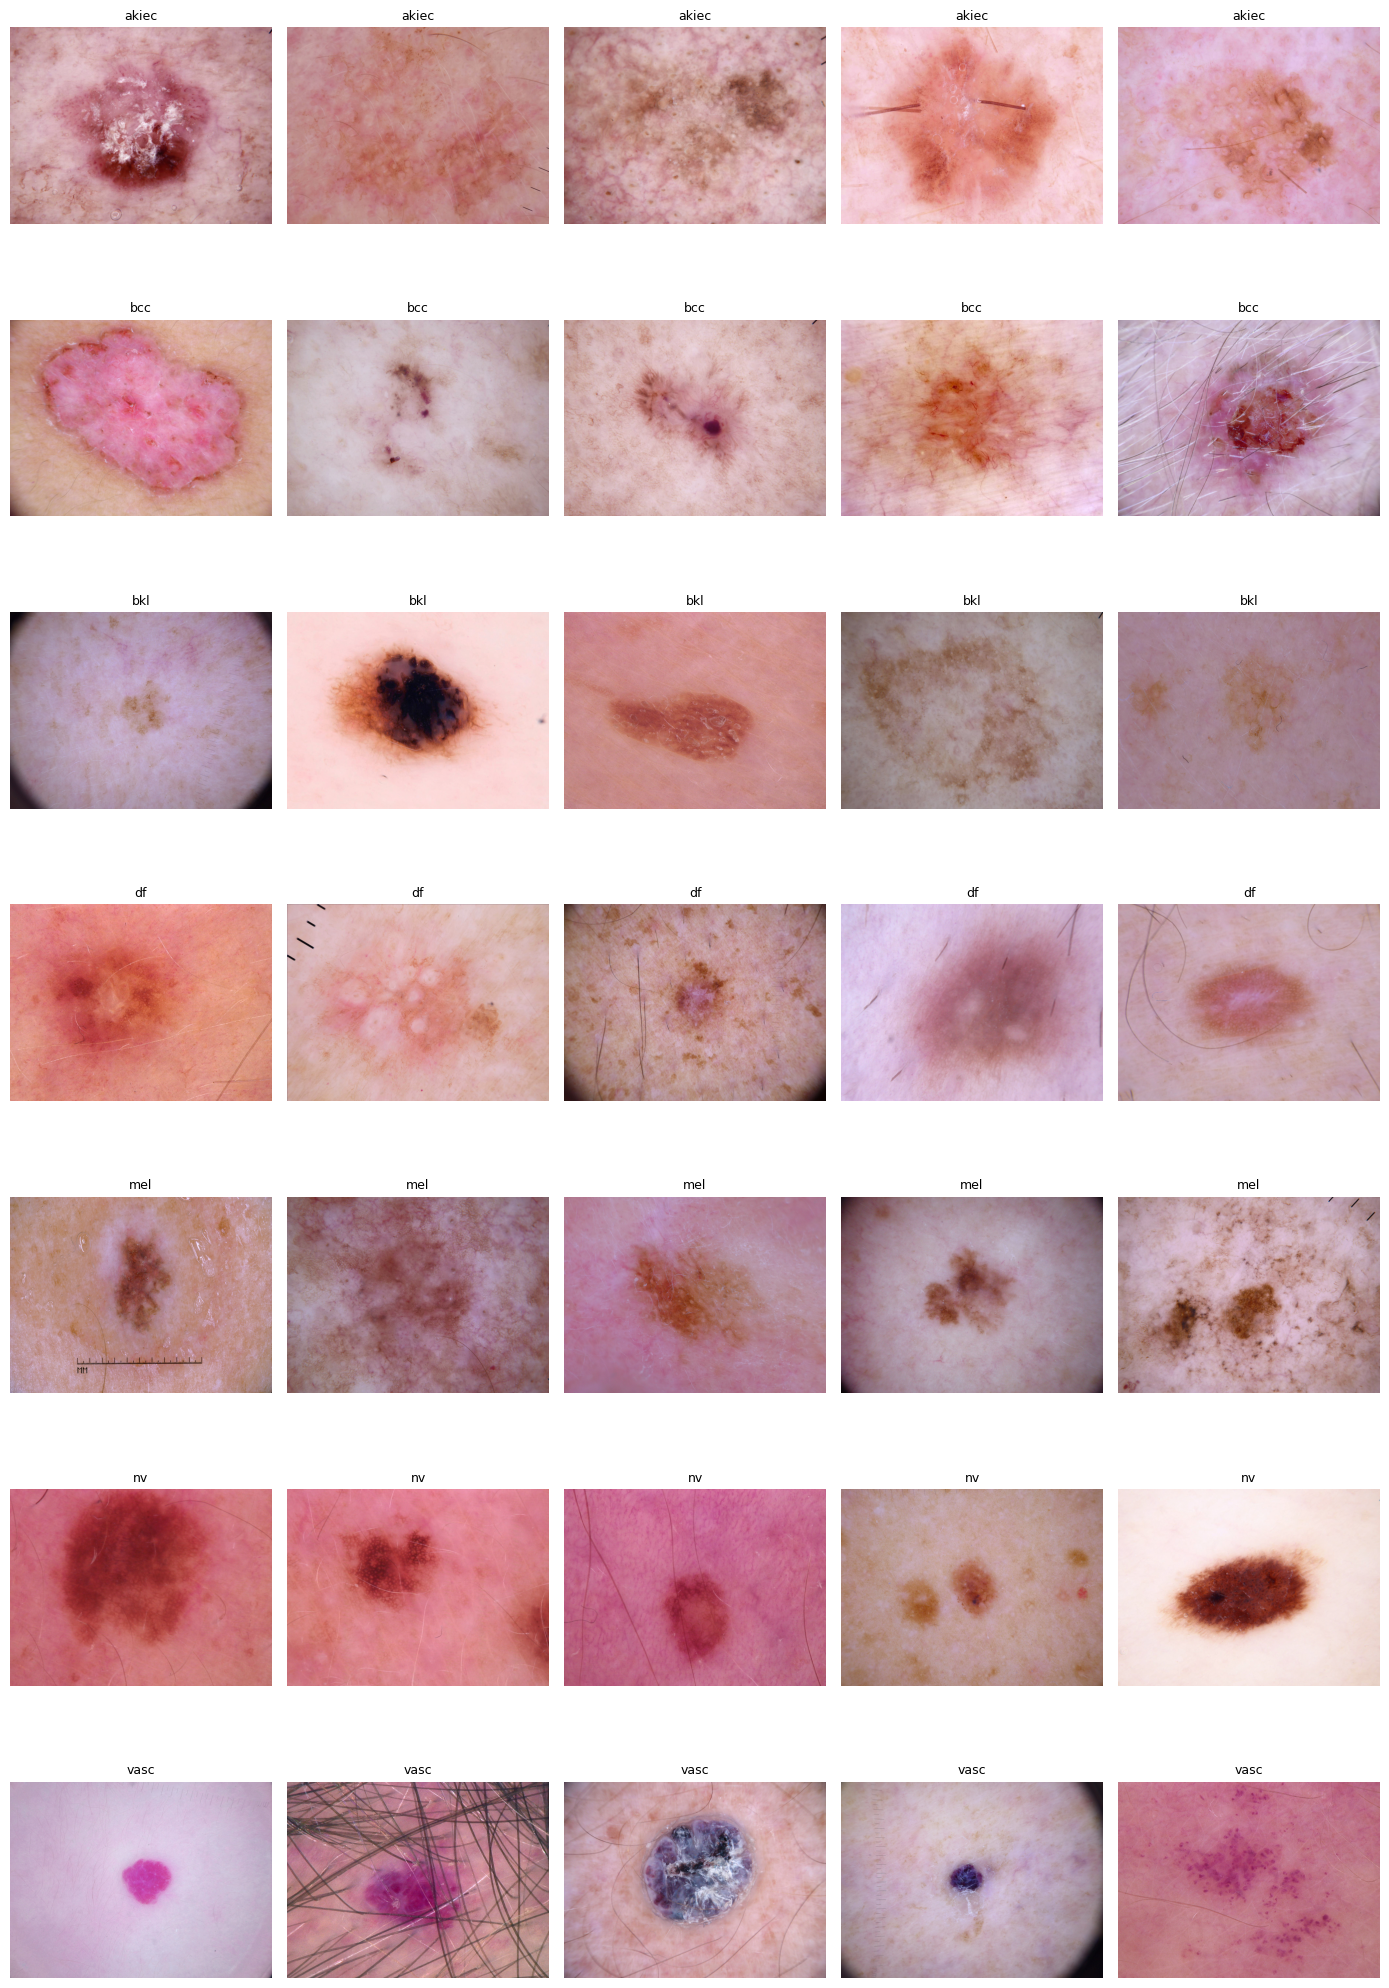

In [10]:

# Task 1.2: Inspect image dimensions, colour modes, and samples

sample = train_df.sample(min(300, len(train_df)), random_state=0)

info = []

for p in sample['path']:
    with Image.open(p) as im:
        info.append({
            'w': im.size[0],
            'h': im.size[1],
            'mode': im.mode
        })

info = pd.DataFrame(info)

print("Image dimensions (sample of up to 300 images):")
print(info.describe().round(0).loc[['min', '50%', 'max']])

print('Colour modes:', info['mode'].value_counts().to_dict())

fig, axes = plt.subplots(len(classes), 5, figsize=(14, 3 * len(classes)))
axes = np.atleast_2d(axes)

for r, c in enumerate(classes):
    paths = train_df[train_df.label == c]['path'].sample(5, random_state=1)

    for ax, p in zip(axes[r], paths):
        with Image.open(p) as im:
            ax.imshow(im.convert('RGB'))
        ax.set_title(c, fontsize=9)
        ax.axis('off')

plt.tight_layout()
plt.show()



### Write it — Dataset Audit and First Shortcut Suspect

The HAM10000 dataset contains 10,015 images across seven classes: akiec (327), bcc (514), bkl (1,099), df (115), mel (1,113), nv (6,705), and vasc (142). The imbalance ratio is 58.30:1, with nv as the largest class and df as the smallest. In a sample of 300 images, all images were RGB colour images measuring 600 × 450 pixels.

**First shortcut suspect:** Background appearance and lighting may differ between classes because of variations in skin photography and image acquisition. These differences are not the diagnostic skin-lesion features the model should learn. This is a preliminary hypothesis from visual inspection, not a confirmed shortcut; further analysis is needed to determine whether background or lighting correlates with the labels.



## Part 2 — Leakage Audit
### Task 2.1 — Detect Exact and Near-Duplicate Images


In [12]:

# Part 2 — Task 2.1: Exact and near-duplicate audit

from scipy.spatial.distance import cdist
from IPython.display import display

DATA_ROOT = '/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000'

# Rebuild image lookup
image_lookup = {}
for folder_name in ['HAM10000_images_part_1', 'HAM10000_images_part_2']:
    folder = os.path.join(DATA_ROOT, folder_name)
    for filename in os.listdir(folder):
        if filename.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tif')):
            image_lookup[os.path.splitext(filename)[0]] = os.path.join(folder, filename)

# Load existing split manifests
train_split = pd.read_csv('/kaggle/working/train_manifest.csv')
val_split = pd.read_csv('/kaggle/working/val_manifest.csv')
test_split = pd.read_csv('/kaggle/working/test_manifest.csv')

train_split['split'] = 'train'
val_split['split'] = 'validation'
test_split['split'] = 'test'

all_df = pd.concat([train_split, val_split, test_split], ignore_index=True)

# Fix diagnosis column name (the manifests may use dx instead of label)
if 'label' not in all_df.columns and 'dx' in all_df.columns:
    all_df['label'] = all_df['dx']

# Support manifests with image_id or file columns
if 'image_id' not in all_df.columns:
    if 'file' in all_df.columns:
        all_df['image_id'] = all_df['file'].map(
            lambda x: os.path.splitext(os.path.basename(str(x)))[0]
        )
    else:
        raise KeyError(f"No image_id or file column found. Columns: {all_df.columns.tolist()}")

# Add image paths
if 'path' not in all_df.columns:
    all_df['path'] = all_df['image_id'].map(
        lambda image_id: image_lookup.get(os.path.splitext(str(image_id))[0])
    )

# Fix paths if they exist but are empty
missing_path = all_df['path'].isna()
all_df.loc[missing_path, 'path'] = all_df.loc[missing_path, 'image_id'].map(
    lambda image_id: image_lookup.get(os.path.splitext(str(image_id))[0])
)

assert all_df['path'].notna().all(), "Some manifest image paths are missing."

# Exact duplicates using MD5
def md5(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

all_df['md5'] = all_df['path'].map(md5)
duplicate_rows = all_df[all_df.duplicated('md5', keep=False)].sort_values('md5')

print("Exact duplicate files:", len(duplicate_rows))

if len(duplicate_rows):
    columns_to_show = ['image_id', 'label', 'split', 'md5']
    print(duplicate_rows[columns_to_show].to_string(index=False))
else:
    print("No exact duplicates found.")

# Fingerprint: standardized 32 x 32 grayscale thumbnail
def fingerprint(path, n=32):
    with Image.open(path) as im:
        arr = np.asarray(
            im.convert('L').resize((n, n)),
            dtype=np.float32
        )
    return ((arr - arr.mean()) / (arr.std() + 1e-6)).flatten()

train_part = all_df[all_df['split'] == 'train'].reset_index(drop=True)
test_part = all_df[all_df['split'] == 'test'].reset_index(drop=True)

train_fp = np.stack([fingerprint(p) for p in train_part['path']])
test_fp = np.stack([fingerprint(p) for p in test_part['path']])

distances = cdist(test_fp, train_fp, metric='cityblock') / train_fp.shape[1]
nearest_idx = distances.argmin(axis=1)
min_distances = distances.min(axis=1)

threshold = 0.10
near_mask = min_distances < threshold
near_indices = np.where(near_mask)[0]

print(f"\nTest images with a near-duplicate in train: {near_mask.sum()} of {len(test_part)}")
print("Five closest distances:", np.sort(min_distances)[:5].round(3))

# Display flagged pairs for visual confirmation
if len(near_indices):
    print("\nInspect these pairs visually before removing anything.")

    for i in near_indices[:20]:
        j = nearest_idx[i]
        test_row = test_part.iloc[i]
        train_row = train_part.iloc[j]

        print(
            f"Distance={min_distances[i]:.4f} | "
            f"Test={test_row['image_id']} ({test_row['label']}) | "
            f"Train={train_row['image_id']} ({train_row['label']})"
        )

        fig, axes = plt.subplots(1, 2, figsize=(7, 3))

        for ax, path, title in [
            (axes[0], train_row['path'], f"Train: {train_row['image_id']}"),
            (axes[1], test_row['path'], f"Test: {test_row['image_id']}")
        ]:
            with Image.open(path) as im:
                ax.imshow(im.convert('RGB'))
            ax.set_title(title)
            ax.axis('off')

        plt.tight_layout()
        plt.show()

    if len(near_indices) > 20:
        print(f"Showing the first 20 of {len(near_indices)} flagged pairs.")
else:
    print("No test-to-train near-duplicate pairs met the threshold.")


Exact duplicate files: 4
    image_id label split                              md5
ISIC_0029861    nv train 38e666ddac3a68dd3fcfc2dcab1c8efa
ISIC_0024366    nv train 38e666ddac3a68dd3fcfc2dcab1c8efa
ISIC_0029938    nv train 7ebfc5926d0717cdce240cbd694a6c98
ISIC_0024777    nv train 7ebfc5926d0717cdce240cbd694a6c98

Test images with a near-duplicate in train: 0 of 2014
Five closest distances: [0.115 0.118 0.124 0.125 0.126]
No test-to-train near-duplicate pairs met the threshold.


### Visual Verification of Exact-Duplicate Pairs

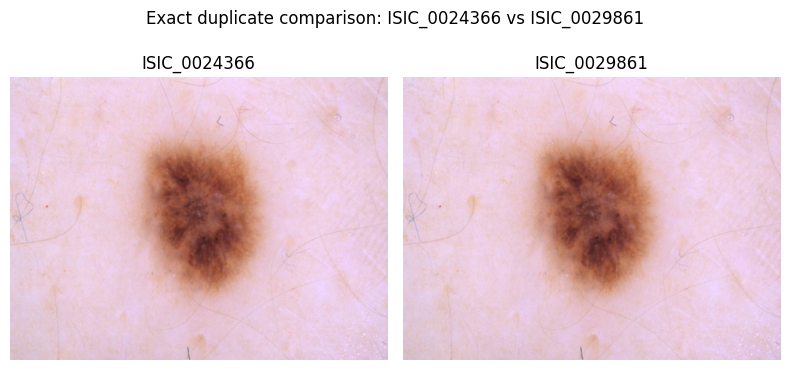

ISIC_0024366 and ISIC_0029861: same MD5 = True


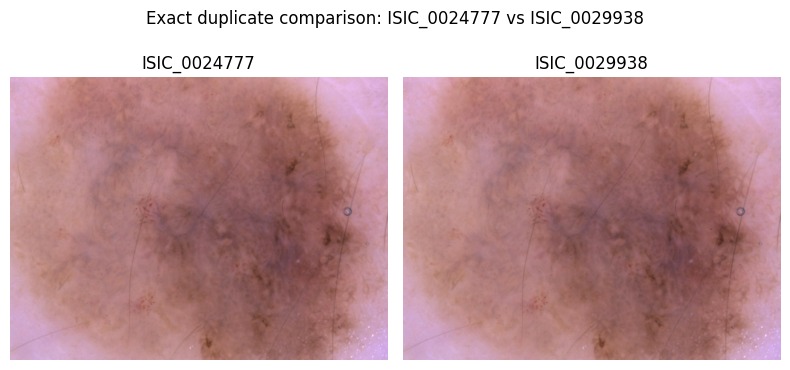

ISIC_0024777 and ISIC_0029938: same MD5 = True


In [13]:

# Visually inspect the two exact-duplicate pairs

exact_pairs = [
    ('ISIC_0024366', 'ISIC_0029861'),
    ('ISIC_0024777', 'ISIC_0029938')
]

for id1, id2 in exact_pairs:
    path1 = image_lookup[id1]
    path2 = image_lookup[id2]

    fig, axes = plt.subplots(1, 2, figsize=(8, 4))

    for ax, path, image_id in [
        (axes[0], path1, id1),
        (axes[1], path2, id2)
    ]:
        with Image.open(path) as im:
            ax.imshow(im.convert('RGB'))
        ax.set_title(image_id)
        ax.axis('off')

    plt.suptitle(f'Exact duplicate comparison: {id1} vs {id2}')
    plt.tight_layout()
    plt.show()

    print(f'{id1} and {id2}: same MD5 =',
          md5(path1) == md5(path2))


### Write it — Task 2.1: Duplicate Verification and Actions

The MD5 audit identified 4 exact-duplicate files forming 2 pairs: ISIC_0024366 and ISIC_0029861, and ISIC_0024777 and ISIC_0029938. All four images belonged to the `nv` class and were in the training split. Both pairs were displayed side by side for visual verification, and their matching MD5 hashes confirmed that each pair was byte-for-byte identical.

The near-duplicate audit compared 2,014 test images against training images using standardized 32 × 32 grayscale fingerprints and a distance threshold of 0.10. No test images had a distance below this threshold. The five smallest distances were 0.115, 0.118, 0.124, 0.125, and 0.126.

No images were deleted. The exact duplicates were retained because both pairs were confined to the training split, and no exact-duplicate or threshold-flagged near-duplicate leakage was detected between training and test. This audit does not rule out every possible form of data leakage.


### Task 2.2 — Split by Group and Verify Leakage Prevention


In [14]:

# Task 2.2: Verify the existing lesion-level group split

# Load the existing manifests created earlier
tr_df = pd.read_csv('/kaggle/working/train_manifest.csv')
va_df = pd.read_csv('/kaggle/working/val_manifest.csv')
test_df = pd.read_csv('/kaggle/working/test_manifest.csv')

# Make sure the group column is available
for df in (tr_df, va_df, test_df):
    if 'group' not in df.columns:
        if 'lesion_id' in df.columns:
            df['group'] = df['lesion_id']
        else:
            raise KeyError(
                f"Cannot find group or lesion_id column. Columns: {df.columns.tolist()}"
            )

# Check for shared lesion groups between each split
train_groups = set(tr_df['group'])
val_groups = set(va_df['group'])
test_groups = set(test_df['group'])

shared_train_val = train_groups & val_groups
shared_train_test = train_groups & test_groups
shared_val_test = val_groups & test_groups

print(f"train {len(tr_df)} | val {len(va_df)} | test {len(test_df)}")
print("Groups shared by train and val:", len(shared_train_val))
print("Groups shared by train and test:", len(shared_train_test))
print("Groups shared by val and test:", len(shared_val_test))

label_col = 'label' if 'label' in va_df.columns else 'dx'
print("\nValidation class counts:")
print(va_df[label_col].value_counts().sort_index().to_string())

assert len(shared_train_val) == 0, "Leakage detected between train and validation!"
assert len(shared_train_test) == 0, "Leakage detected between train and test!"
assert len(shared_val_test) == 0, "Leakage detected between validation and test!"

print("\nPASS: No lesion groups are shared between the three splits.")


train 6380 | val 1621 | test 2014
Groups shared by train and val: 0
Groups shared by train and test: 0
Groups shared by val and test: 0

Validation class counts:
dx
akiec      51
bcc        85
bkl       189
df         18
mel       208
nv       1043
vasc       27

PASS: No lesion groups are shared between the three splits.



### Write it — Leakage Audit Summary

The exact-duplicate audit found 4 files forming 2 identical pairs: ISIC_0024366 and ISIC_0029861, and ISIC_0024777 and ISIC_0029938; both pairs were entirely within the training split. The near-duplicate audit found 0 test-to-train matches below the 0.10 threshold among 2,014 test images, and no images were deleted. The dataset contains 10,015 images and 7,470 unique lesion groups, averaging 1.34 images per group.

If the images had been split randomly rather than by lesion group, images of the same lesion could have appeared in both training and test sets. This could have made the test score look artificially higher because the model might recognize lesion-specific visual patterns instead of generalizing to unseen lesions.



## Part 3 — Transforms and Class Imbalance
### Task 3.1 — Define Datasets and Image Transforms


In [16]:

# Part 3 — Task 3.1: Datasets and transforms

DATA_ROOT = '/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000'
IMG_SIZE = 224
GRAYSCALE = False

# Build image ID -> file path lookup
image_lookup = {}
for folder_name in ['HAM10000_images_part_1', 'HAM10000_images_part_2']:
    folder = os.path.join(DATA_ROOT, folder_name)
    for filename in os.listdir(folder):
        if filename.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tif')):
            image_lookup[os.path.splitext(filename)[0]] = os.path.join(folder, filename)

# Restore paths and labels from the saved manifests
for df in (tr_df, va_df, test_df):
    if 'image_id' not in df.columns:
        raise KeyError(f"Missing image_id. Available columns: {df.columns.tolist()}")

    df['path'] = df['image_id'].map(
        lambda x: image_lookup.get(os.path.splitext(str(x))[0])
    )

    if 'label' not in df.columns and 'dx' in df.columns:
        df['label'] = df['dx']

    if df['path'].isna().any():
        raise ValueError(f"Missing image paths: {df['path'].isna().sum()}")

# Class names and labels
classes = sorted(tr_df['label'].unique())
print("Classes:", classes)

MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

to_rgb = [transforms.Grayscale(num_output_channels=3)] if GRAYSCALE else []

train_tf = transforms.Compose(to_rgb + [
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

eval_tf = transforms.Compose(to_rgb + [
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

class ImageTable(Dataset):
    def __init__(self, df, tf):
        self.paths = df['path'].tolist()
        class_to_idx = {c: i for i, c in enumerate(classes)}
        self.y = df['label'].map(class_to_idx).tolist()
        self.tf = tf

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        with Image.open(self.paths[i]) as img:
            img = img.convert('RGB')
            img = self.tf(img)
        return img, self.y[i]

train_ds = ImageTable(tr_df, train_tf)
val_ds = ImageTable(va_df, eval_tf)
test_ds = ImageTable(test_df, eval_tf)

print("Training dataset size:", len(train_ds))
print("Validation dataset size:", len(val_ds))
print("Test dataset size:", len(test_ds))
print("Image size:", IMG_SIZE, "x", IMG_SIZE)
print("Grayscale:", GRAYSCALE)
print("Missing paths across splits:",
      tr_df['path'].isna().sum() +
      va_df['path'].isna().sum() +
      test_df['path'].isna().sum())


Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Training dataset size: 6380
Validation dataset size: 1621
Test dataset size: 2014
Image size: 224 x 224
Grayscale: False
Missing paths across splits: 0


In [17]:

from torchvision import transforms

IMG_SIZE = 224

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        IMG_SIZE,
        scale=(0.8, 1.0)
    ),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Apply the transforms to the existing datasets
train_ds.transform = train_transform
val_ds.transform = eval_transform
test_ds.transform = eval_transform

print("Training augmentation configured.")
print("Image size:", IMG_SIZE, "x", IMG_SIZE)
print("Training: random crop, rotation, brightness and contrast.")
print("Validation/test: resize and normalize only.")
print("Horizontal and vertical flips: not used.")


Training augmentation configured.
Image size: 224 x 224
Training: random crop, rotation, brightness and contrast.
Validation/test: resize and normalize only.
Horizontal and vertical flips: not used.


### Write it — Data Augmentation

Mild data augmentation was configured for the HAM10000 skin-lesion classification task. During training, images are randomly cropped and resized to 224 × 224 pixels, rotated by up to 10 degrees, and adjusted slightly in brightness and contrast. These transformations are intended to improve robustness to variations in image framing, orientation, and appearance.

Horizontal and vertical flips are not used. Validation and test images undergo resizing and normalization only, ensuring consistent evaluation without random augmentation. The augmentation configuration was successfully applied to the existing training, validation, and test datasets. Its effect on model performance will be assessed using validation results rather than assumed in advance.

### Task 3.2 — Class Weights and Balanced Sampling

In [18]:

import numpy as np
import torch
from torch.utils.data import DataLoader, WeightedRandomSampler

# Count training images in each class
n_c = np.bincount(train_ds.y, minlength=len(classes))

# Calculate class weights: N / (K * n_c)
class_w = len(train_ds) / (len(classes) * n_c)

print("Training images:", len(train_ds))
print("Number of classes:", len(classes))
print("\nClass counts and weights:")

for cls, count, weight in zip(classes, n_c, class_w):
    print(f"{cls}: count={count}, weight={weight:.3f}")

# Use weighted loss first, as required
loss_w = torch.tensor(
    class_w, dtype=torch.float32, device=device
)

USE_SAMPLER = False

if USE_SAMPLER:
    sample_w = class_w[train_ds.y]
    sampler = WeightedRandomSampler(
        torch.as_tensor(sample_w, dtype=torch.double),
        len(sample_w),
        replacement=True
    )
    train_dl = DataLoader(
        train_ds, batch_size=32, sampler=sampler, num_workers=2
    )
    loss_w = None
else:
    train_dl = DataLoader(
        train_ds, batch_size=32, shuffle=True, num_workers=2
    )

val_dl = DataLoader(
    val_ds, batch_size=64, shuffle=False, num_workers=2
)
test_dl = DataLoader(
    test_ds, batch_size=64, shuffle=False, num_workers=2
)

print("\nUSE_SAMPLER:", USE_SAMPLER)
print("Training batches:", len(train_dl))
print("Validation batches:", len(val_dl))
print("Test batches:", len(test_dl))
print("Weighted loss enabled:", loss_w is not None)


Training images: 6380
Number of classes: 7

Class counts and weights:
akiec: count=208, weight=4.382
bcc: count=329, weight=2.770
bkl: count=705, weight=1.293
df: count=75, weight=12.152
mel: count=683, weight=1.334
nv: count=4299, weight=0.212
vasc: count=81, weight=11.252

USE_SAMPLER: False
Training batches: 200
Validation batches: 26
Test batches: 32
Weighted loss enabled: True


### Write it — Task 3.2: Class Weights and Augmentation Choices

The training dataset contains 6,380 images across seven diagnostic classes. Class weights were calculated using \(w_c = N/(K \times n_c)\), where \(N=6380\), \(K=7\), and \(n_c\) is the number of training images in each class.

The calculated weights are: akiec = 4.382, bcc = 2.770, bkl = 1.293, df = 12.152, mel = 1.334, nv = 0.212, and vasc = 11.252.

For example, the weight for dermatofibroma (df), which has 75 training images, is:

\[
w_{\text{df}}=\frac{6380}{7\times75}
=\frac{6380}{525}\approx12.152
\]

The rare classes receive higher weights, while the majority class, nv, receives the lowest weight. Weighted loss was selected for the initial experiment, with balanced sampling disabled.

For augmentation, mild random resized cropping (scale 0.8–1.0), rotations of up to 10 degrees, and brightness and contrast adjustments of 0.15 were retained. These transformations introduce variation in image framing, orientation, and appearance while aiming to preserve useful lesion features. Horizontal and vertical flips were excluded in this experiment to avoid introducing unnecessary transformations. Validation and test images use resizing and normalization only so that evaluation remains consistent. The impact of these choices will be assessed using actual validation results.

# Part 4 — Build and Train
### Task 4.1 — Pretrained Backbone with a New Classification Head

In [21]:

import torch
import torch.nn as nn
from torchvision import models

def build_model(name, n_classes):
    if name == "resnet18":
        m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4

    elif name == "resnet50":
        m = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4

    elif name == "efficientnet_b0":
        weights = models.EfficientNet_B0_Weights.DEFAULT
        m = models.efficientnet_b0(weights=weights)
        m.classifier[1] = nn.Linear(
            m.classifier[1].in_features, n_classes
        )
        body, head, last = m, m.classifier, m.features[-1]

    else:
        raise ValueError(f"Unsupported backbone: {name}")

    # Freeze all pretrained parameters
    for p in body.parameters():
        p.requires_grad = False

    # Train the new classification head
    for p in head.parameters():
        p.requires_grad = True

    return m.to(device), head, last


model, head, last_block = build_model(BACKBONE, len(classes))

trainable = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)
total = sum(p.numel() for p in model.parameters())

print("Backbone:", BACKBONE)
print("Number of classes:", len(classes))
print("Trainable parameters:", f"{trainable:,}")
print("Total parameters:", f"{total:,}")
print("Frozen backbone:", True)
print("New classification head:", head)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 179MB/s] 


Backbone: resnet18
Number of classes: 7
Trainable parameters: 3,591
Total parameters: 11,180,103
Frozen backbone: True
New classification head: Linear(in_features=512, out_features=7, bias=True)


In [20]:

BACKBONE = "resnet18"

print("Selected backbone:", BACKBONE)


Selected backbone: resnet18


### Write it — Task 4.1: Pretrained Backbone and Classification Head
A pretrained ResNet18 model with ImageNet weights was selected as the backbone for the HAM10000 seven-class skin-lesion classification task. The original classification layer was replaced with a new fully connected layer that maps 512 input features to seven output classes.

The model contains 11,180,103 parameters in total, of which 3,591 are trainable. The pretrained backbone was frozen, while the new classification head was left trainable. This approach allows the new head to learn the target diagnostic classes while preserving the pretrained feature-extraction weights during the initial training stage. The model was loaded successfully.

### Task 4.2 — Two-Phase Training with Macro-F1 Model Selection

In [22]:

import copy
import time
import torch
import torch.nn.functional as F
from sklearn.metrics import f1_score

def predict(model, loader):
    model.eval()
    probs, ys = [], []

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            probs.append(F.softmax(model(xb), dim=1).cpu())
            ys.append(yb.cpu())

    return torch.cat(probs).numpy(), torch.cat(ys).numpy()


def fit(model, params, epochs, lr):
    opt = torch.optim.Adam(params, lr=lr)
    best, best_state = -1, None

    for ep in range(epochs):
        model.train()
        t0 = time.time()

        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)

            loss = F.cross_entropy(
                model(xb), yb, weight=loss_w
            )

            opt.zero_grad()
            loss.backward()
            opt.step()

        p, y = predict(model, val_dl)
        macro = f1_score(
            y, p.argmax(1), average="macro", zero_division=0
        )

        print(
            f"epoch {ep + 1}: val macro-F1 {macro:.3f} "
            f"({time.time() - t0:.0f}s)"
        )

        if macro > best:
            best = macro
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    return best


# Phase 1: train the new classification head only
print("Phase 1: head only")
phase1_best = fit(
    model, head.parameters(), epochs=2, lr=1e-3
)
print(f"Phase 1 best validation Macro-F1: {phase1_best:.3f}")


# Phase 2: unfreeze the final backbone block and fine-tune it
print("\nPhase 2: fine-tune the last block")

for p in last_block.parameters():
    p.requires_grad = True

phase2_best = fit(
    model,
    [
        {"params": last_block.parameters(), "lr": 1e-4},
        {"params": head.parameters(), "lr": 1e-3},
    ],
    epochs=3,
    lr=1e-3
)

print(f"Phase 2 best validation Macro-F1: {phase2_best:.3f}")


Phase 1: head only
epoch 1: val macro-F1 0.454 (57s)
epoch 2: val macro-F1 0.433 (56s)
Phase 1 best validation Macro-F1: 0.454

Phase 2: fine-tune the last block
epoch 1: val macro-F1 0.562 (56s)
epoch 2: val macro-F1 0.563 (56s)
epoch 3: val macro-F1 0.638 (56s)
Phase 2 best validation Macro-F1: 0.638


### Write it — Task 4.2: Two-Phase Training Results

During Phase 1, only the classification head was trained for two epochs. The validation Macro-F1 scores were **0.454** in epoch 1 and **0.433** in epoch 2, giving a best Phase 1 score of **0.454**.

During Phase 2, the final ResNet18 block was unfrozen and fine-tuned alongside the classification head for three epochs. The validation Macro-F1 scores were **0.562**, **0.563**, and **0.638**, respectively. The best Phase 2 score was **0.638** in epoch 3.

Fine-tuning helped: the best validation Macro-F1 increased by **0.184**, from 0.454 to 0.638. Each epoch took approximately **56–57 seconds**, or about 56 seconds on average.

With more time, I would run approximately **5–10 additional fine-tuning epochs**, using a lower learning rate if needed and continuing to select checkpoints by validation Macro-F1. I would monitor the validation scores for signs of overfitting and stop if performance stopped improving. The additional epochs are a proposed experiment, not completed training results.

# Part 5 — Test Once, and Set the Threshold
### Task 5.1 — Test-Set Classification Report and Confusion Matrix

Test-set classification report:
              precision    recall  f1-score   support

       akiec      0.429     0.706     0.533        68
         bcc      0.420     0.730     0.533       100
         bkl      0.504     0.585     0.542       205
          df      0.385     0.227     0.286        22
         mel      0.483     0.563     0.520       222
          nv      0.940     0.811     0.871      1363
        vasc      0.585     0.706     0.640        34

    accuracy                          0.745      2014
   macro avg      0.535     0.618     0.561      2014
weighted avg      0.790     0.745     0.760      2014

Test Macro-F1: 0.561


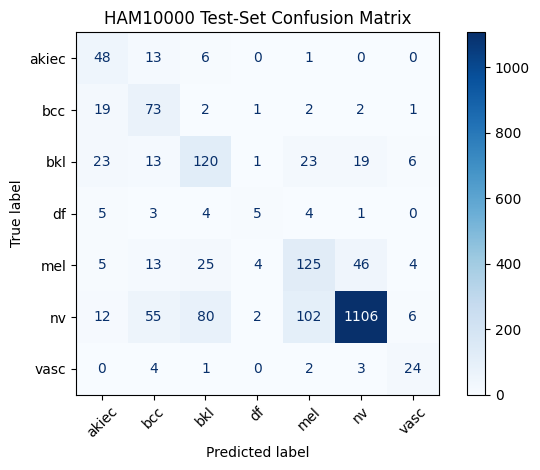

In [24]:

from sklearn.metrics import (
    classification_report,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Evaluate the selected model on the held-out test set
p_test, y_test = predict(model, test_dl)
pred = p_test.argmax(axis=1)

print("Test-set classification report:")
print(
    classification_report(
        y_test,
        pred,
        labels=list(range(len(classes))),
        target_names=classes,
        digits=3,
        zero_division=0
    )
)

test_macro_f1 = f1_score(
    y_test, pred, average="macro", zero_division=0
)
print("Test Macro-F1:", round(test_macro_f1, 3))

cm = confusion_matrix(
    y_test, pred, labels=list(range(len(classes)))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)
disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("HAM10000 Test-Set Confusion Matrix")
plt.tight_layout()
plt.show()


### Write it — Task 5.1: Test-Set Evaluation

The selected ResNet18 model was evaluated on the held-out test set of 2,014 images. The model achieved an accuracy of 0.745, a Macro-F1 score of 0.561, and a weighted F1 score of 0.760.

The highest per-class F1 score was obtained for melanocytic nevi (`nv`), at 0.871. The lowest was for dermatofibroma (`df`), at 0.286. The `df` class had only 22 test images, while `nv` had 1,363, illustrating the challenge posed by class imbalance. The results show that the model performs unevenly across diagnostic categories, so accuracy alone would not adequately describe its performance.

The confusion matrix was generated to examine which classes were predicted correctly and which were confused with other classes. These test results provide the final evaluation of the current model; further model selection or tuning should rely on the validation set rather than repeated experimentation on the test set.

### Task 5.2 — Per-Class Recall Analysis (Multiclass Task)

In [25]:
from sklearn.metrics import recall_score, classification_report
import pandas as pd

per_class_recall = recall_score(
    y_test,
    pred,
    labels=list(range(len(classes))),
    average=None,
    zero_division=0
)

recall_df = pd.DataFrame({
    "Class": classes,
    "Test Recall": per_class_recall
})

print("Per-class test recall:")
print(recall_df.to_string(index=False))

Per-class test recall:
Class  Test Recall
akiec     0.705882
  bcc     0.730000
  bkl     0.585366
   df     0.227273
  mel     0.563063
   nv     0.811445
 vasc     0.705882


In [26]:
from sklearn.metrics import confusion_matrix

# Treat melanoma (mel) as positive and all other classes as negative
mel_idx = classes.index("mel")

y_true_binary = (y_test == mel_idx)
y_pred_binary = (pred == mel_idx)

tn, fp, fn, tp = confusion_matrix(
    y_true_binary, y_pred_binary, labels=[False, True]
).ravel()

sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)

print(f"TP: {tp}, FN: {fn}, TN: {tn}, FP: {fp}")
print(f"Sensitivity: {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")

TP: 125, FN: 97, TN: 1658, FP: 134
Sensitivity: 0.5631
Specificity: 0.9252


In [27]:
prevalence = 0.05

numerator = sensitivity * prevalence
false_positive_term = (1 - specificity) * (1 - prevalence)
denominator = numerator + false_positive_term
ppv = numerator / denominator

print(f"Numerator = {sensitivity:.4f} × 0.05 = {numerator:.4f}")
print(
    f"False-positive term = (1 - {specificity:.4f}) × 0.95 "
    f"= {false_positive_term:.4f}"
)
print(f"PPV = {numerator:.4f} / {denominator:.4f} = {ppv:.4f}")
print(f"PPV = {ppv * 100:.2f}%")

Numerator = 0.5631 × 0.05 = 0.0282
False-positive term = (1 - 0.9252) × 0.95 = 0.0710
PPV = 0.0282 / 0.0992 = 0.2838
PPV = 28.38%


### Write it — Part 5: Test Evaluation and Prevalence

The ResNet18 model achieved a test Macro-F1 score of **0.561** and an accuracy of **0.745** on the 2,014-image test set. The weakest class was dermatofibroma (`df`), with an F1 score of **0.286** and recall of **0.227**. The strongest class by F1 score was melanocytic nevi (`nv`), at **0.871**.

Because this is a seven-class classification task, binary threshold selection and the binary target-recall requirement are not applicable. Instead, per-class recall was analysed.

For an illustrative binary analysis, melanoma (`mel`) was treated as the positive class and all other classes as negative. The test results gave 125 true positives, 97 false negatives, 1,658 true negatives, and 134 false positives. This corresponds to a sensitivity of **0.5631** and a specificity of **0.9252**.

Using an assumed prevalence of 5%, the positive predictive value (PPV) was calculated as:

PPV = (Sensitivity × Prevalence) / [(Sensitivity × Prevalence) + ((1 − Specificity) × (1 − Prevalence))]

PPV = (0.5631 × 0.05) / [(0.5631 × 0.05) + ((1 − 0.9252) × 0.95)]

PPV ≈ **28.38%**.

PPV depends on the prevalence of the positive class in the population. At a lower prevalence, false positives can make up a large proportion of all positive predictions, even when specificity is relatively high. At a higher prevalence, a greater proportion of positive predictions are expected to be true positives, assuming sensitivity and specificity remain the same. The 5% prevalence is an illustrative assumption, not a verified prevalence for the intended population.

# Part 6 — Grad-CAM Shortcut Check
### Task 6.1 — Visualizing Correct and Incorrect Predictions

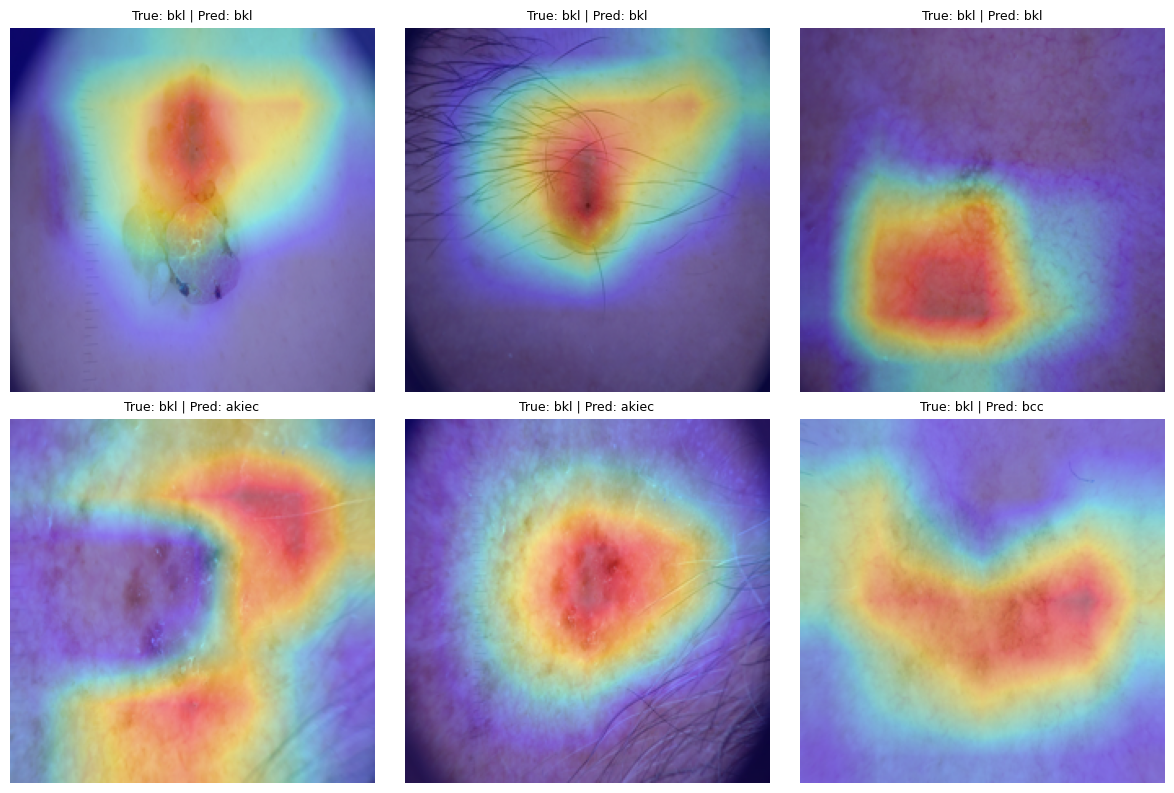

In [28]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

class GradCAM:
    def __init__(self, model, layer):
        self.model = model
        self.acts = None
        self.grads = None

        layer.register_forward_hook(self._save_act)
        layer.register_full_backward_hook(self._save_grad)

    def _save_act(self, module, inputs, output):
        self.acts = output.detach()

    def _save_grad(self, module, grad_input, grad_output):
        self.grads = grad_output[0].detach()

    def __call__(self, x, cls=None):
        self.model.eval()
        x = x.unsqueeze(0).to(device)

        logits = self.model(x)
        cls = int(logits.argmax(dim=1).item()) if cls is None else cls

        self.model.zero_grad()
        logits[0, cls].backward()

        alpha = self.grads.mean(dim=(2, 3), keepdim=True)
        cam_map = F.relu((alpha * self.acts).sum(dim=1))

        cam_map = F.interpolate(
            cam_map.unsqueeze(1),
            size=x.shape[-2:],
            mode="bilinear",
            align_corners=False
        ).squeeze()

        cam_map = cam_map / (cam_map.max() + 1e-8)
        return cam_map.detach().cpu().numpy(), cls


# Enable gradients for Grad-CAM
for p in model.parameters():
    p.requires_grad = True

cam = GradCAM(model, last_block)

# Find three correct and three incorrect test predictions
wrong = np.where(pred != y_test)[0][:3].tolist()
right = np.where(pred == y_test)[0][:3].tolist()

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, i in zip(axes.flat, right + wrong):
    x, y = test_ds[i]
    heat, predicted_class = cam(x)

    img = Image.open(test_ds.paths[i]).convert("RGB")
    img = img.resize((IMG_SIZE, IMG_SIZE))

    ax.imshow(img)
    ax.imshow(heat, cmap="jet", alpha=0.4)
    ax.set_title(
        f"True: {classes[y]} | Pred: {classes[predicted_class]}",
        fontsize=9
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

### Write it — Task 6.1: Grad-CAM Shortcut Check

**Analysis of the six heatmaps**

1. **Correct prediction 1 (true: bkl, predicted: bkl):** The model focused on the central lesion. This is potentially legitimate evidence because lesion appearance is relevant to classification.
2. **Correct prediction 2 (true: bkl, predicted: bkl):** The attention overlapped the central lesion region. This is potentially legitimate evidence, although the heatmap alone cannot establish which lesion features were used.
3. **Correct prediction 3 (true: bkl, predicted: bkl):** The model concentrated attention around the lesion. This is potentially legitimate evidence if the highlighted region contains relevant lesion characteristics.
4. **Incorrect prediction 1 (true: bkl, predicted: akiec):** The attention formed a ring around the lesion. This raises the possibility that surrounding skin texture influenced the prediction, although the highlighted border may also contain relevant lesion information.
5. **Incorrect prediction 2 (true: bkl, predicted: akiec):** The attention was more centred but diffuse. This may reflect relevant lesion features, but the visualization does not identify the exact cause of the misclassification.
6. **Incorrect prediction 3 (true: bkl, predicted: bcc):** The attention appeared in two distinct regions near the lesion. These regions may contain relevant border or lesion features; the heatmap alone cannot confirm that the model relied on an inappropriate shortcut.

**Overall verdict: Shortcut suspected.**

The heatmaps raise a possible concern that surrounding skin or other image regions may influence some predictions, particularly in misclassified examples. However, shortcut learning is not confirmed by these six visualizations alone.

**Proposed experiment:** Crop each image to retain the lesion while removing as much surrounding skin as possible, then apply the same preprocessing and model to the original and cropped images. Compare the predicted classes, class probabilities, and Macro-F1 across a larger, representative test sample. If predictions or performance change substantially after removing the surrounding context, this would support the possibility that the model relies on contextual features. The experiment should preserve the lesion itself as much as possible and use the same evaluation procedure for both conditions.

### Optional Task — OCR for Document Projects

This task was skipped because the project uses the HAM10000 skin-lesion image dataset rather than document images. Optical Character Recognition (OCR) is intended to extract text from images, so it is not relevant to the current skin-lesion classification task. Therefore, EasyOCR was not installed or executed.

# Part 7 — Save and Document

In [29]:
import torch
from pathlib import Path

save_path = "/kaggle/working/week6_model.pt"

torch.save({
    "state_dict": model.state_dict(),
    "classes": classes,
    "backbone": BACKBONE,
    "img_size": IMG_SIZE,
    "grayscale": GRAYSCALE
}, save_path)

print(f"Saved model to: {save_path}")
print(f"File exists: {Path(save_path).exists()}")

Saved model to: /kaggle/working/week6_model.pt
File exists: True


### Write it — Part 7: Save and Document

The trained ResNet18 model was saved to `/kaggle/working/week6_model.pt`. The checkpoint contains the model's state dictionary, the seven class labels, the backbone name, the image size, and the grayscale configuration. These details help preserve the trained model and its essential configuration for future loading and inference.

The saved model can be downloaded from the Kaggle notebook's output files after verifying that the file was created successfully.

# Check Your Understanding — Answers

### 1. Why does a random split of chest X-rays overestimate performance?

A random image-level split may place images from the same patient in both the training and test sets. Because images from one patient can share characteristics, the model may recognize patient-specific patterns rather than learn features that generalize to unseen patients. This causes data leakage and can lead to an overly optimistic test score. Patient-level splitting helps prevent this problem.

### 2. Two classes have 900 and 100 training images. Compute both class weights using \(N/(K \times n_c)\).

**Given:**

- Total training images: \(N=900+100=1000\)
- Number of classes: \(K=2\)

**Class 1 (900 images):**

\[
w_1=\frac{1000}{2\times900}
=\frac{1000}{1800}\approx\boxed{0.556}
\]

**Class 2 (100 images):**

\[
w_2=\frac{1000}{2\times100}
=\frac{1000}{200}=\boxed{5.0}
\]

The minority class receives a higher weight so that its errors contribute more strongly to the weighted loss.

### 3. With focal loss and \(\gamma=2\), by what factor is an example with \(p_t=0.8\) down-weighted?

The focal loss modulation factor is:

\[
(1-p_t)^\gamma
\]

Substituting the values:

\[
(1-0.8)^2=(0.2)^2=\boxed{0.04}
\]

Therefore, the example's loss is multiplied by **0.04**, or 4% of its original cross-entropy loss, assuming the same class-weighting factor. This reduces the contribution of an example the model already predicts confidently.

### 4. Sensitivity = 0.90, specificity = 0.95, prevalence = 2%. Compute PPV.

**Formula:**

\[
PPV=\frac{Sensitivity\times Prevalence}
{(Sensitivity\times Prevalence)+(1-Specificity)\times(1-Prevalence)}
\]

Substitute the values:

\[
PPV=\frac{0.90\times0.02}
{(0.90\times0.02)+(1-0.95)\times(1-0.02)}
\]

Calculate the numerator:

\[
0.90\times0.02=0.018
\]

Calculate the false-positive term:

\[
(1-0.95)\times0.98=0.05\times0.98=0.049
\]

Calculate PPV:

\[
PPV=\frac{0.018}{0.018+0.049}
=\frac{0.018}{0.067}
\approx\boxed{0.2687=26.87\%}
\]

Despite high sensitivity and specificity, PPV is approximately **26.87%** because prevalence is low.

### 5. When is Macro-F1 a better selection metric than weighted F1?

Macro-F1 is preferable when every class should have equal importance, especially when the dataset is imbalanced and performance on minority classes matters. It calculates F1 separately for each class and averages the scores equally. Weighted F1 gives more influence to classes with more examples, so strong performance on a majority class can hide poor performance on rare classes.

### 6. Grad-CAM highlights a hospital label in the corner of X-rays. What do you do next?

This raises a concern about possible shortcut learning because the hospital label is not a medical feature of the disease. I would first inspect more heatmaps to see whether this pattern occurs consistently. Then I would mask or crop out the label and compare the model's predictions and performance on the same images with the original results. I would also evaluate the model on data without the label, ideally from a different hospital. If performance changes substantially when the label is removed, that would support the shortcut hypothesis. I would then retrain or improve the dataset and validate the changes on an independent test set.